# Mandatory assignment 3

**GitHub repository:** *(https://github.com/bergjacob/TECH2-H26-assignment3)*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [340]:
#Importing pandas, numpy and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [341]:
#Loading the file into a pandas dataframe
DATA = 'SCF_10pct.csv'
df = pd.read_csv(DATA, sep=',')

#Printing the columns contained in the dataframe and their numbers of non-missing values
print(df.count())
print(f'The total length of the DataFrame is: {len(df)}')

print('')

#Defining the current amounts of observations
idLength = df.count()['id']
yearLength = df.count()['year']
ageLength = idLengt = df.count()['age']
educLength = df.count()['educ']
stocksLength = df.count()['stocks']
equityLength = df.count()['equity']

#Drops rows that do not have information about either stocks, equity or education. Year, age and ID was included in every row, so it was unneccesary to include it in the algorithm here
for i in df['id']:
   if pd.isna(df.loc[i, 'stocks']) or pd.isna(df.loc[i, 'equity']) or pd.isna(df.loc[i, 'educ']):
      df = df.drop(i)

#Printing how many of each observation that were dropped
print('Variable     Dropped       Remain')
print(f'ID {idLength-df.count()["id"]:>12} {df.count()["id"]:>15}')
print(f'Year {yearLength-df.count()["year"]:>10} {df.count()["year"]:>15}')
print(f'Age {ageLength-df.count()["age"]:>11} {df.count()["age"]:>15}')
print(f'Education {educLength-df.count()["educ"]:>5} {df.count()["educ"]:>15}')
print(f'Stocks {stocksLength-df.count()["stocks"]:>8} {df.count()["stocks"]:>15}')
print(f'Equity {equityLength-df.count()["equity"]:>8} {df.count()["equity"]:>15}')

id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64
The total length of the DataFrame is: 5808

Variable     Dropped       Remain
ID           50            5758
Year         50            5758
Age          50            5758
Education    34            5758
Stocks       32            5758
Equity       34            5758


In [342]:
oldLength = len(df)
#Drops rows that do not fulfill 25 <= age <= 89
for i in df['id']:
  if not (25 <= df.loc[i, 'age'] <= 89):
    df = df.drop(i)


#Print the change of observation
print(f'{oldLength - len(df)} observations were removed. {len(df)} remain.')

326 observations were removed. 5432 remain.


4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [343]:
#Making two lists for the indicator columns (IC), so we do not mess with the dataframe while going through it
directPartIC = []
overallPartIC = []

#Going through the dataframe
for i in df['id']:
    if df.loc[i, 'stocks'] > 0:
        directPartIC.append(1)
    else:
        directPartIC.append(0)

    if df.loc[i, 'equity'] > 0:
        overallPartIC.append(1)
    else:
        overallPartIC.append(0)

#Inserting the ICs to the dataframe
df['directPartIC'] = directPartIC
df['overallPartIC'] = overallPartIC

df

,id,year,age,educ,stocks,equity,directPartIC,overallPartIC
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [344]:
def participation_rate(indicator: list) -> float:
    """
    @Param:
        indicator: nonempty one-dimensional sequence of 0/1 values
    ----------
    @returns the fraction of ones (in percent)
    """
    total = len(indicator)

    try:
        fraction = (indicator.sum()/total)*100   #The sum can be used because it only consists of 0 and 1
    except:
        sum = 0
        for i in indicator:
            sum += i
        fraction = (sum/total)*100

    return(fraction)



print(f'The direct participation rate is {participation_rate(df['directPartIC']):.2f}%')
print(f'The overall participation rate is {participation_rate(df['overallPartIC']):.2f}%')




The direct participation rate is 16.96%
The overall participation rate is 49.41%


In [345]:

#Using pandas built in DataFrame.mean() method
print(f'The direct participation rate is {df['directPartIC'].mean()*100:.2f}%')
print(f'The overall participation rate is {df['overallPartIC'].mean()*100:.2f}%')


The direct participation rate is 16.96%
The overall participation rate is 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [346]:

def sortEduc(degree:int) -> dict:
    """
    @param
        degree : the degree of education. Has to be 1, 2, 3 or 4

    -----------
    returns a dictionary containing lists of direct participation (directPartIC) and overall participation (overallPartIC) as binary values
    """
    if 1 <= degree <= 4 and degree == int(degree):
        participation = {'directPartIC': [], 'overallPartIC': []}
        for i in df['id']:
            if df.loc[i, 'educ'] == degree:
                participation['directPartIC'].append(df.loc[i, 'directPartIC'])
                participation['overallPartIC'].append(df.loc[i, 'overallPartIC'])

        return pd.DataFrame(participation)

    else:
        print('The degree of education has to be 1, 2, 3 or 4')

In [347]:
#Using pandas built in DataFrame.mean() method and a for-loop to print the participation rates for the different education degrees

for degree in range(1, 5):
    print(f'Education degree {degree}:')
    print(f'    Direct participation rate: {sortEduc(degree)['directPartIC'].mean()*100:>6.1f}%')
    print(f'    Overall participation rate: {sortEduc(degree)['overallPartIC'].mean()*100:>5.1f}%')
    print('')

Education degree 1:
    Direct participation rate:    4.4%
    Overall participation rate:  17.3%

Education degree 2:
    Direct participation rate:   11.4%
    Overall participation rate:  39.9%

Education degree 3:
    Direct participation rate:   13.5%
    Overall participation rate:  48.3%

Education degree 4:
    Direct participation rate:   30.5%
    Overall participation rate:  73.5%



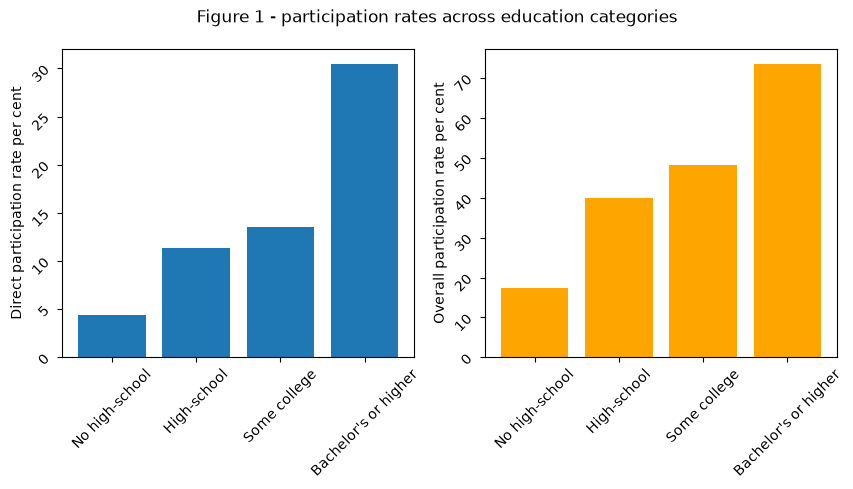

Both measures show that people with higher education tend to invest more in stocks 
than people with a lower education. The gap between bachelor's degree and the 
rest is lower in the equity measure than in the direct stocks measure


In [348]:
#Make a list of the degrees, and lists of the values.
education_degrees = ['No high-school', 'High-school', 'Some college', "Bachelor's or higher"]
y_values_dir = []
y_values_ov = []
for degree in range(1,5):
    y_values_dir.append(sortEduc(degree)['directPartIC'].mean()*100)
    y_values_ov.append(sortEduc(degree)['overallPartIC'].mean()*100)    


#Creating a figure with two subplots
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Setting chart zero about direct participation rate
ax[0].bar(education_degrees, y_values_dir)
ax[0].set_ylabel('Direct participation rate per cent')
ax[0].tick_params(rotation=45)

# Setting chart one about direct participation rate
ax[1].bar(education_degrees, y_values_ov, color='orange')
ax[1].set_ylabel('Overall participation rate per cent')
ax[1].tick_params(rotation=45)

# Setting a title for the figure and showing it
fig.suptitle('Figure 1 - participation rates across education categories')
plt.show()

#Commenting on the graphs
print(f"Both measures show that people with higher education tend to invest more in stocks \nthan people with a lower education. The gap between bachelor's degree and the \nrest is lower in the equity measure than in the direct stocks measure")

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

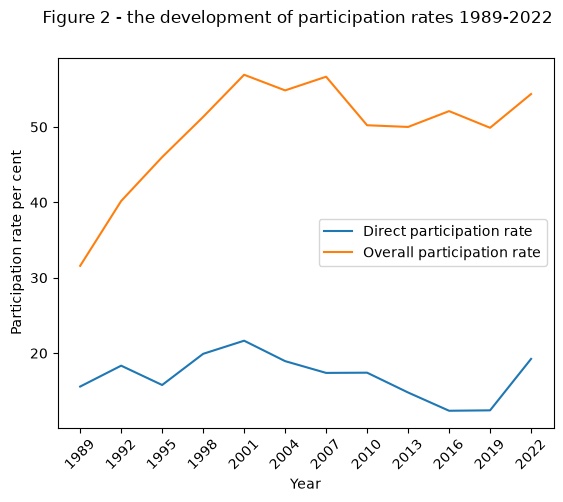

The direct participation rate increased by 3.67 pp from 1989 to 2022
The overall participation rate increased by 22.78 pp from 1989 to 2022

Both participation rates were increasing from 1989 until 2001. Then they were 
falling with a winding pattern towards 2019. From 2019 to 2922, both were 
increasing again, and ending up at a point higher than where it started.


In [356]:
#Making a dictionary for the participation rates per year
partPerYear = {}

for i in df['id']:

    #Compares to previous year if it is not the first year
    if i != df.iloc[0]['id']:
        previousYear = currentYear
        currentYear = df.loc[i, 'year']


        #Checking if the year changed of if we are on the last iteration
        if previousYear != currentYear or i == df.iloc[-1]['id']:
            #Add the lists of the previous year to the dictionary partPerYear
            partPerYear[f'{previousYear}'] = {'directPartIC': tempDirect, 'overallPartIC': tempOverall}
            
            #Resets the temporary lists
            tempDirect = []
            tempOverall = []
            
        else:
            #appends the values to the temporary lists
            tempDirect.append(df.loc[i, 'directPartIC'])
            tempOverall.append(df.loc[i, 'overallPartIC'])


    #defines the current year and the temporary lists for the current year
    else:
        currentYear = df.loc[i, 'year']
        tempDirect = []        
        tempOverall = []

        #appends the values of this iteration to the temporary lists
        tempDirect.append(df.loc[i, 'directPartIC'])
        tempOverall.append(df.loc[i, 'overallPartIC'])
        


#Define lists which are used to plot on the abscissa and ordinate axises.
x_values = []
y_values_dir2 = []
y_values_ov2 = []

#Appending the values to the lists
for year in partPerYear:
    x_values.append(year)
    y_values_dir2.append(participation_rate(partPerYear[f'{year}']['directPartIC']))
    y_values_ov2.append(participation_rate(partPerYear[f'{year}']['overallPartIC']))


# plot the values, add labes
plt.plot(x_values, y_values_dir2, label = 'Direct participation rate')
plt.plot(x_values, y_values_ov2, label='Overall participation rate')
plt.xlabel('Year')
plt.ylabel('Participation rate per cent')

#Rotate the labels for the years, so they are not in front of one another
plt.xticks(rotation=45)


#Show labels, add suptitle, show the figure
plt.legend()
plt.suptitle('Figure 2 - the development of participation rates 1989-2022')
plt.show()

#Comment on the percentage points
print(f'The direct participation rate increased by {y_values_dir2[-1]-y_values_dir2[0]:.2f} pp from 1989 to 2022')
print(f'The overall participation rate increased by {y_values_ov2[-1]-y_values_ov2[0]:.2f} pp from 1989 to 2022')

print('')

#Comment on the development
print(f'Both participation rates were increasing from 1989 until 2001. Then they were \nfalling with a winding pattern towards 2019. From 2019 to 2922, both were \nincreasing again, and ending up at a point higher than where it started.')

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

AI was used to look up some syntaxes.